# 72 · A conditional VAE policy: a latent variable that chooses the mode (the core idea of ACT)

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.toy_envs import AroundObstacleEnv, collect_around

torch.manual_seed(0)
H, Z = 10, 2

def chunks(eps):
    X, Y = [], []
    for e in eps:
        T = len(e["act"])
        for t in range(T):
            idx = np.minimum(np.arange(t, t + H), T - 1)
            X.append(e["obs"][t]); Y.append(e["act"][idx].reshape(-1))
    return torch.tensor(np.array(X)), torch.tensor(np.array(Y))

class CVAE(nn.Module):
    def __init__(self, d_obs=4, d_act=2 * H, z=Z, h=256):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_obs + d_act, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 2 * z))
        self.dec = nn.Sequential(nn.Linear(d_obs + z, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, d_act))
    def forward(self, o, a):
        mu, logvar = self.enc(torch.cat([o, a], -1)).chunk(2, -1)
        z = mu + (0.5 * logvar).exp() * torch.randn_like(mu)
        return self.dec(torch.cat([o, z], -1)), mu, logvar
    def act(self, o, z):
        return self.dec(torch.cat([o, z], -1))

def train(beta, epochs=150):
    torch.manual_seed(0); model = CVAE(); opt = torch.optim.Adam(model.parameters(), 1e-3)
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(256):
            rec, mu, logvar = model(X[idx], Y[idx])
            l_rec = (rec - Y[idx]).abs().mean()
            kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(-1).mean()
            loss = l_rec + beta * kl; opt.zero_grad(); loss.backward(); opt.step()
    return model, l_rec.item(), kl.item()

def run(model, z_mode, n=30):
    env, out, paths = AroundObstacleEnv(), [], []
    for s in range(n):
        o = env.reset(seed=500 + s); z = torch.zeros(Z) if z_mode == "zero" else torch.randn(Z)
        done, path, queue = False, [env.pos()], []
        while not done:
            if not queue:
                with torch.no_grad():
                    queue = list(model.act(torch.tensor(o), z).view(H, 2).numpy()[: H // 2])
            o, _, done, info = env.step(queue.pop(0)); path.append(env.pos())
        out.append(info); paths.append(np.array(path))
    return out, paths

In [2]:
eps = collect_around(200, seed=0)
X, Y = chunks(eps)
model, l_rec, kl = train(beta=0.01)
print(f"reconstruction L1 {l_rec:.3f}, KL {kl:.3f}")

reconstruction L1 0.018, KL 0.502


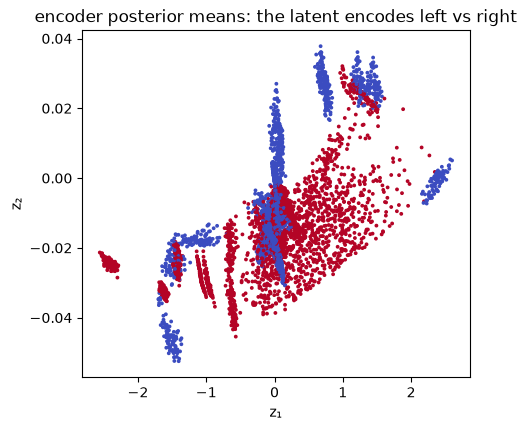

In [3]:
with torch.no_grad():
    mu, _ = model.enc(torch.cat([X, Y], -1)).chunk(2, -1)
side = np.concatenate([[e["side"]] * len(e["act"]) for e in eps])
plt.figure(figsize=(5, 4.5)); plt.scatter(mu[:, 0], mu[:, 1], c=side, cmap="coolwarm", s=3)
plt.xlabel("z₁"); plt.ylabel("z₂"); plt.title("encoder posterior means: the latent encodes left vs right"); plt.show()

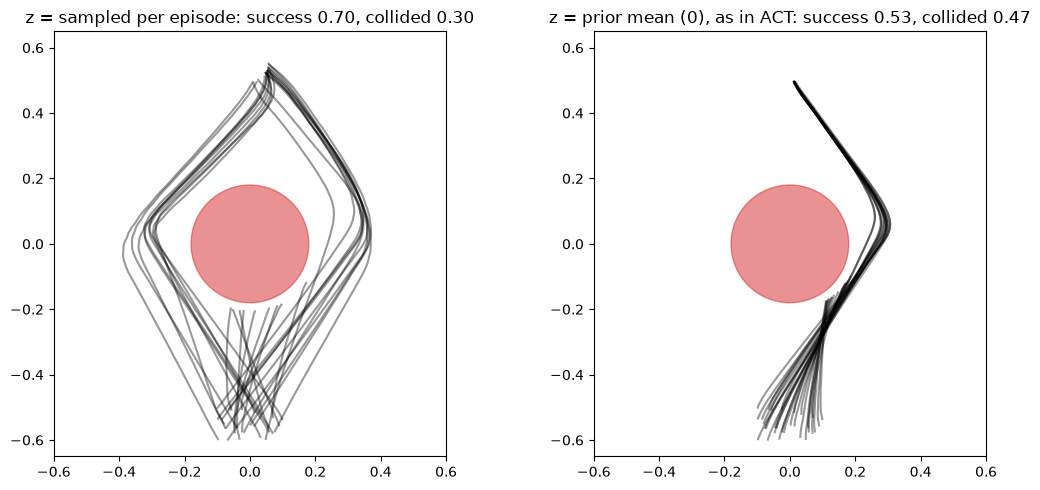

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mode in zip(axes, ["sample", "zero"]):
    res, paths = run(model, mode)
    ax.add_patch(plt.Circle((0, 0), 0.18, color="tab:red", alpha=0.5)); ax.set_aspect("equal"); ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.65, 0.65)
    for p in paths:
        ax.plot(p[:, 0], p[:, 1], "k", alpha=0.4)
    ax.set_title(f"z = {'sampled per episode' if mode == 'sample' else 'prior mean (0), as in ACT'}: success {np.mean([r['success'] for r in res]):.2f}, collided {np.mean([r['collided'] for r in res]):.2f}")
plt.tight_layout(); plt.show()

In [5]:
for beta in [0.0, 0.01, 1.0]:
    m, lr, k = train(beta, epochs=80)
    res, _ = run(m, "sample", 20)
    print(f"β={beta:<5} rec {lr:.3f}  KL {k:6.3f}  success with sampled z {np.mean([r['success'] for r in res]):.2f}")

β=0.0   rec 0.009  KL 15.798  success with sampled z 0.00


β=0.01  rec 0.018  KL  0.559  success with sampled z 0.85


β=1.0   rec 0.027  KL  0.000  success with sampled z 0.20
